# T5: short-period recovery

Redraws every figure in `README.md` from the committed tables in `data/` (the drawing code is in
`figures.py`). The tables come from the scripts listed in the README's *Reproduce* section.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import figures as F
pd.set_option('display.width', 200)
d = F.load_phase1()

## 1. Diagnosis: where the true sub-day peak sits
Rank (by raw power) of the true-period peak for detectable <1 d stars, and how many spectral peaks compete
for the 10 slots as the baseline grows.

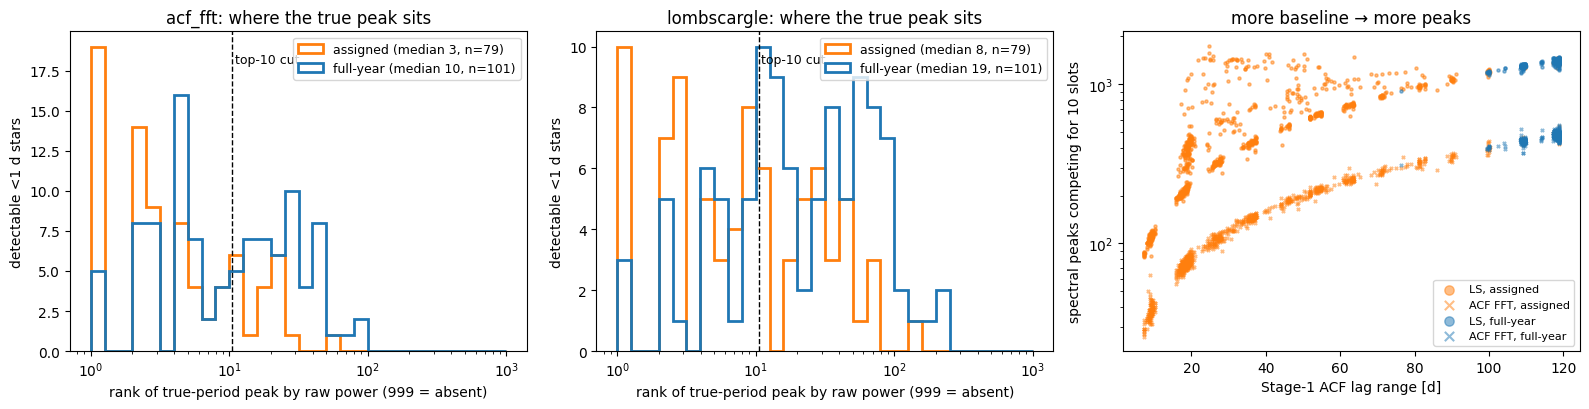

In [2]:
F.fig_rank(d); plt.show()

Example stars, both coverage modes: light curve, ACF, ACF-FFT spectrum, Lomb-Scargle. Red = true
period (band = diffrot range or ±10%), grey triangles = old top-10, green = picks the hybrid ranking adds.

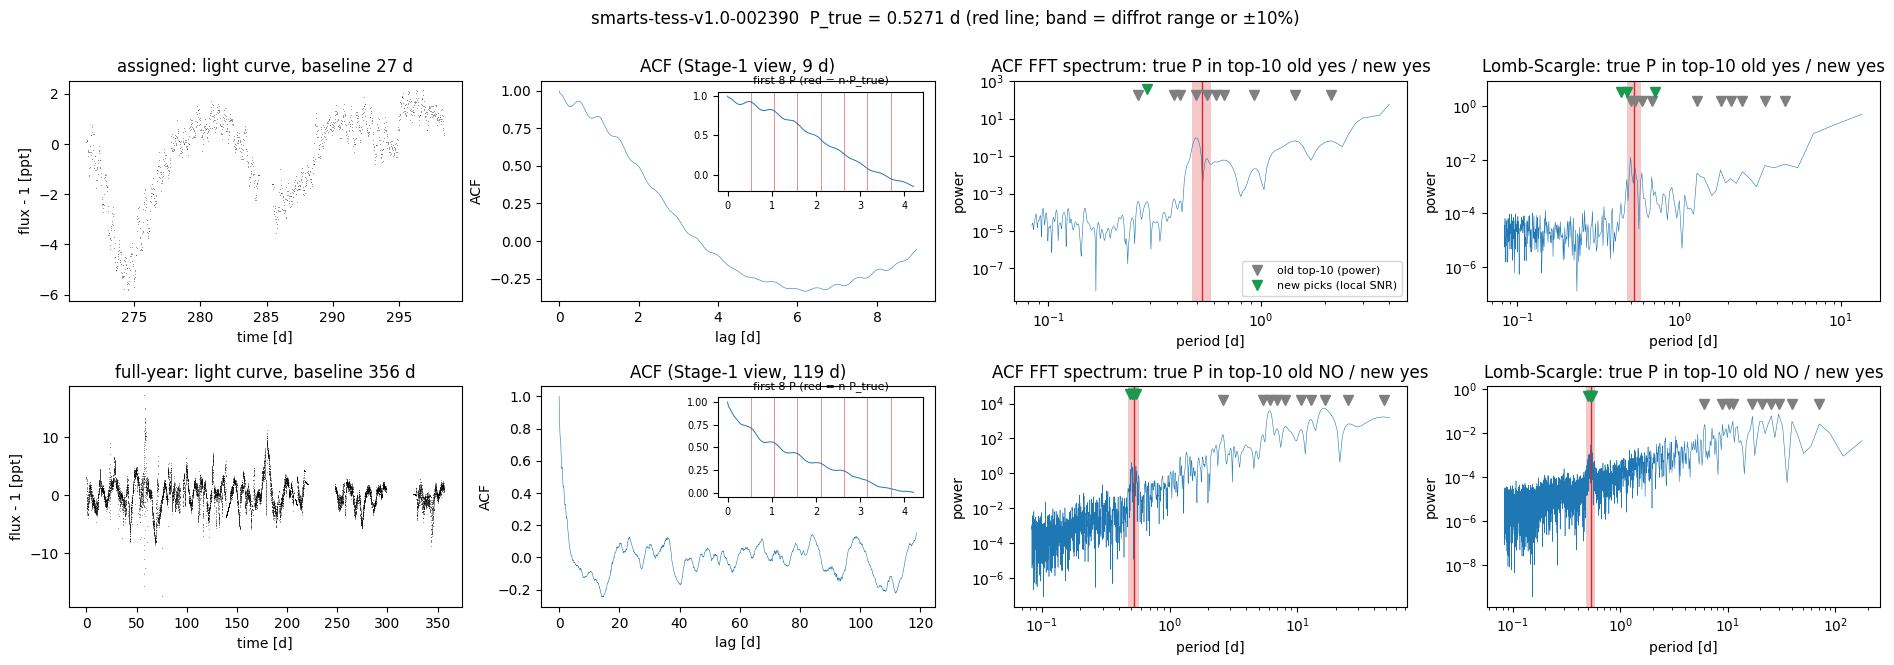

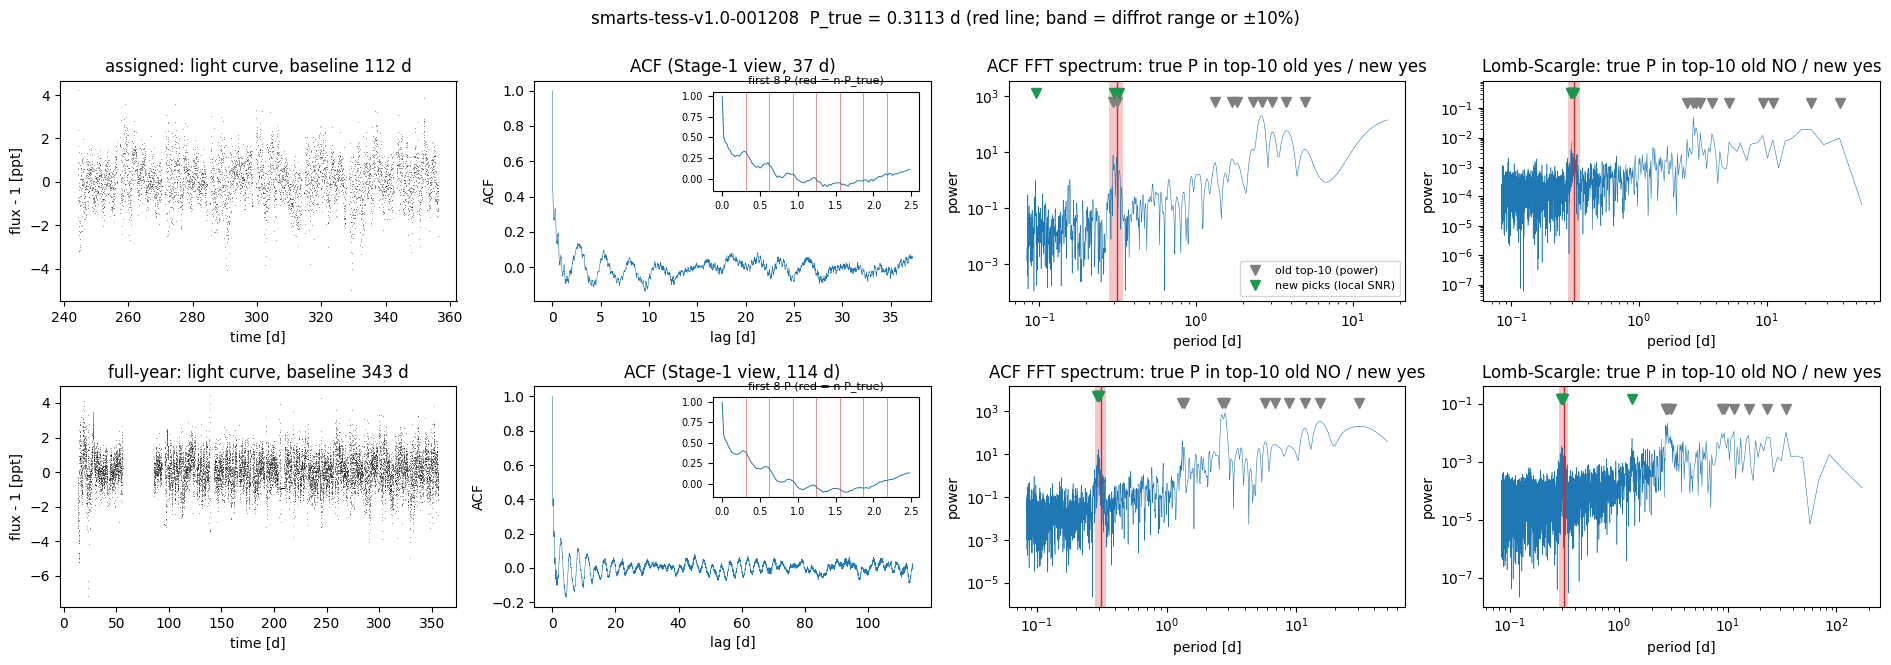

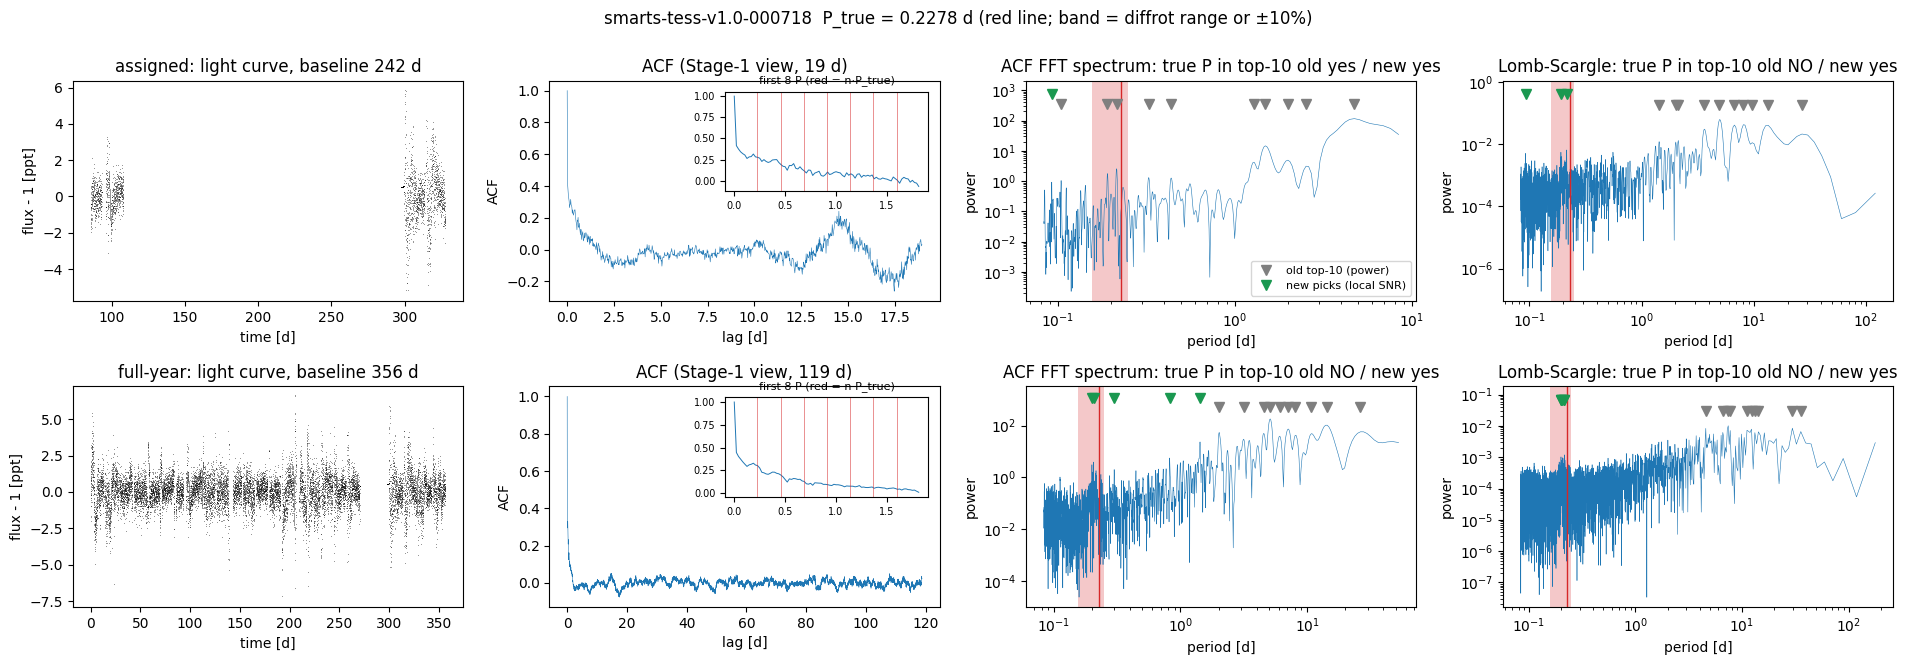

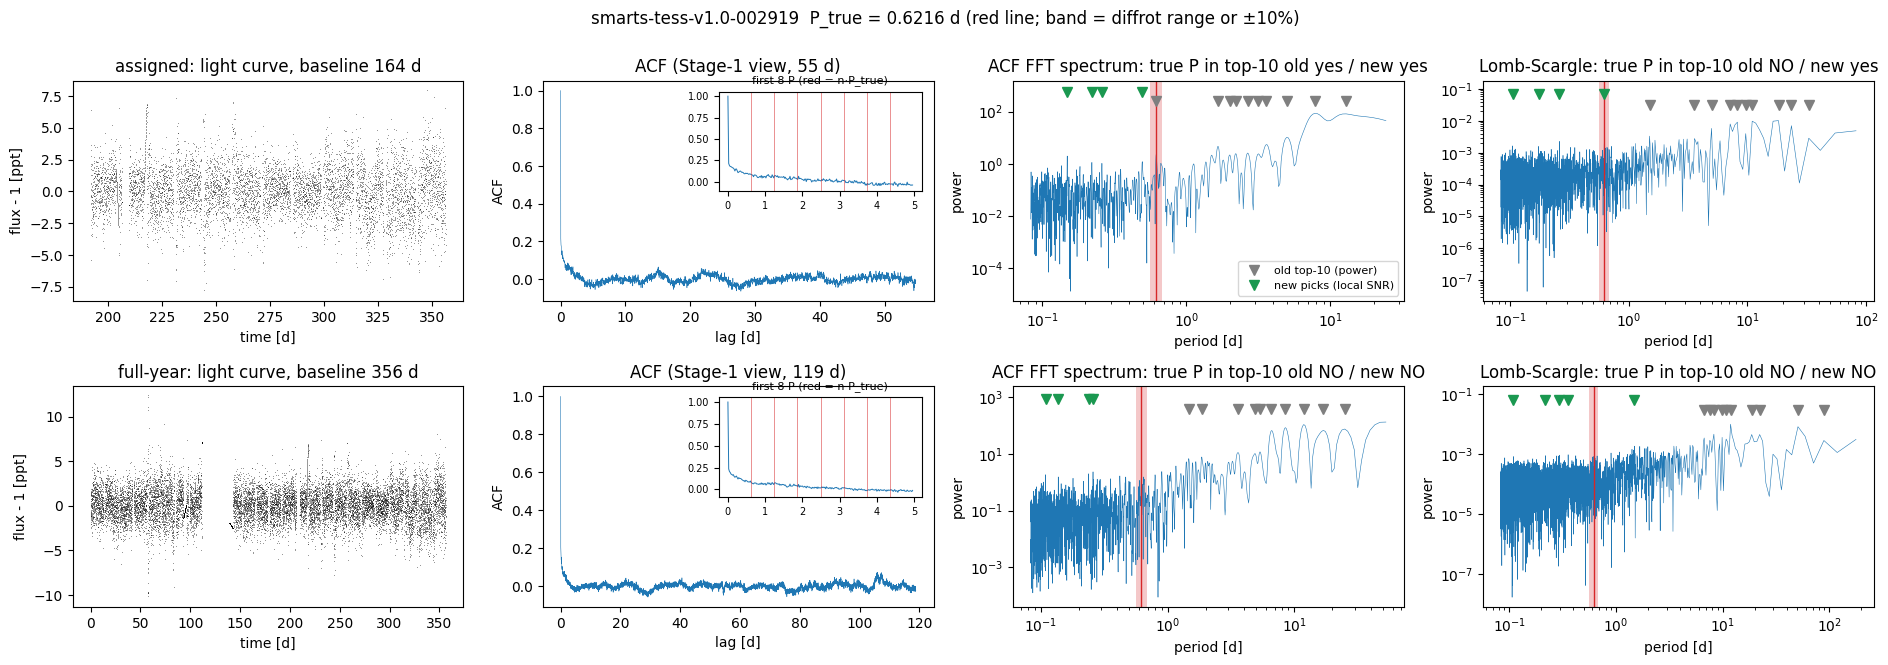

In [3]:
for s in ['smarts-tess-v1.0-002390', 'smarts-tess-v1.0-001208', 'smarts-tess-v1.0-000718', 'smarts-tess-v1.0-002919']:
    F.fig_diag(s); plt.show()

## 2. Stage-1 recall before / after the ranking fix

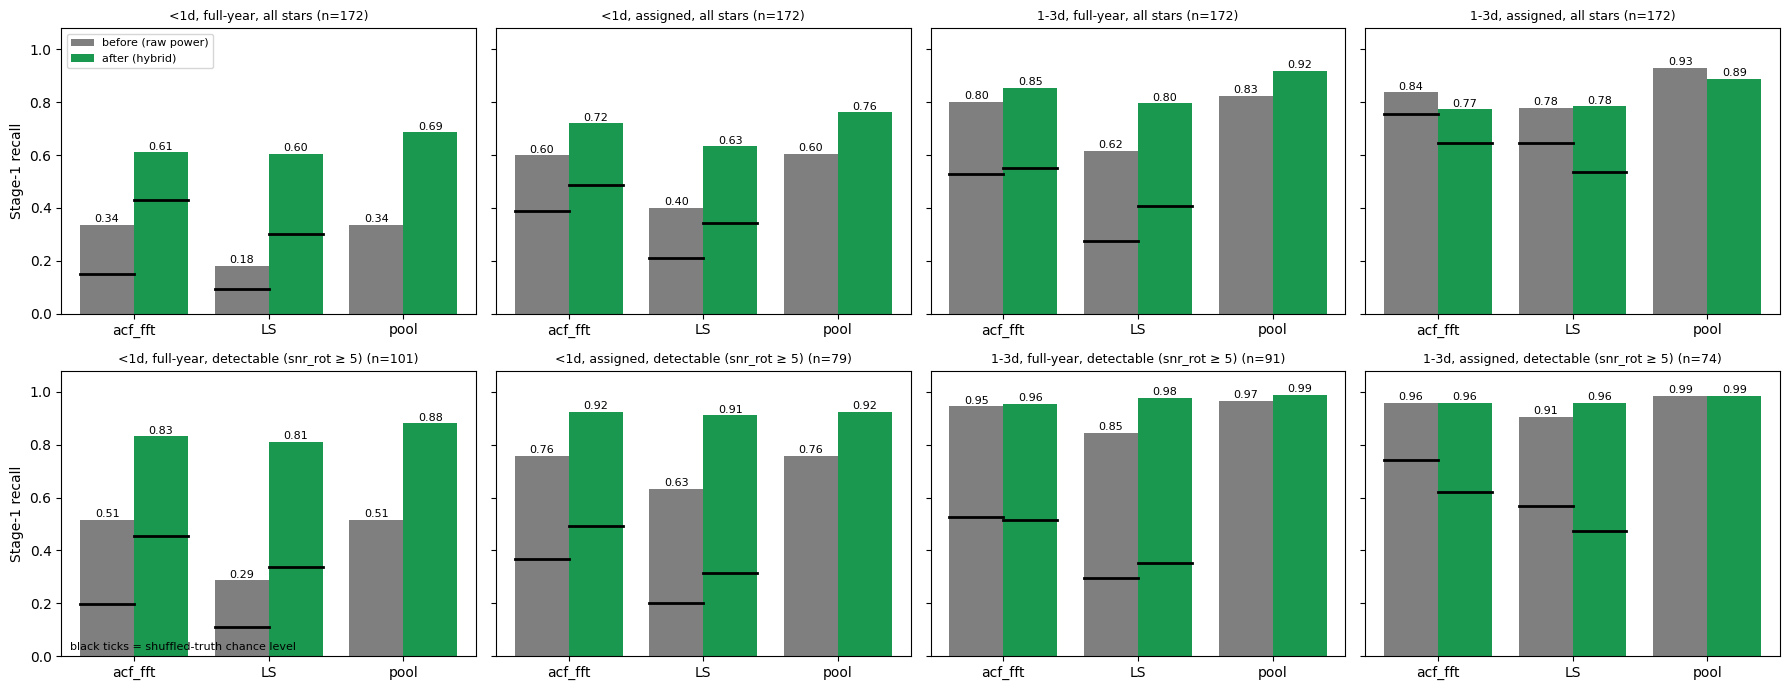

In [4]:
F.fig_stage1_before_after(d); plt.show()

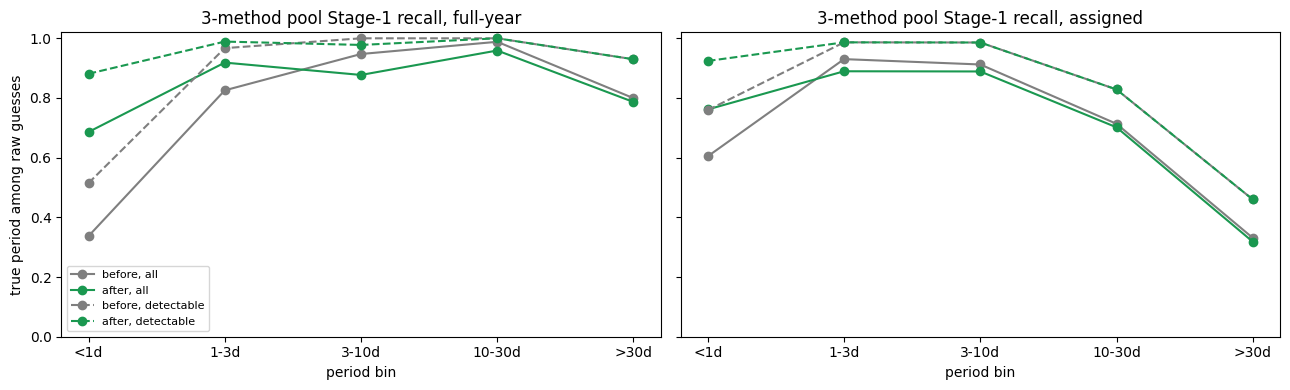

In [5]:
F.fig_stage1_all_bins(d); plt.show()

In [6]:
t = d.groupby(['mode', 'eval_pbin'])[['old_pool', 'new_pool']].mean()
t.join(d[d.detectable].groupby(['mode', 'eval_pbin'])[['old_pool', 'new_pool']].mean(), rsuffix='_detectable').round(3)

old_pool  new_pool  old_pool_detectable  new_pool_detectable
mode eval_pbin                                                              
asg  1-3d          0.930     0.890                0.986                0.986
     10-30d        0.713     0.702                0.829                0.829
     3-10d         0.912     0.889                0.986                0.986
     <1d           0.605     0.762                0.759                0.924
     >30d          0.331     0.318                0.460                0.460
fy   1-3d          0.826     0.919                0.967                0.989
     10-30d        0.988     0.959                1.000                1.000
     3-10d         0.947     0.877                1.000                0.978
     <1d           0.337     0.686                0.515                0.881
     >30d          0.799     0.787                0.930                0.930

## 3. Scorecard: final outcomes and fitted-candidate ceiling, before vs after

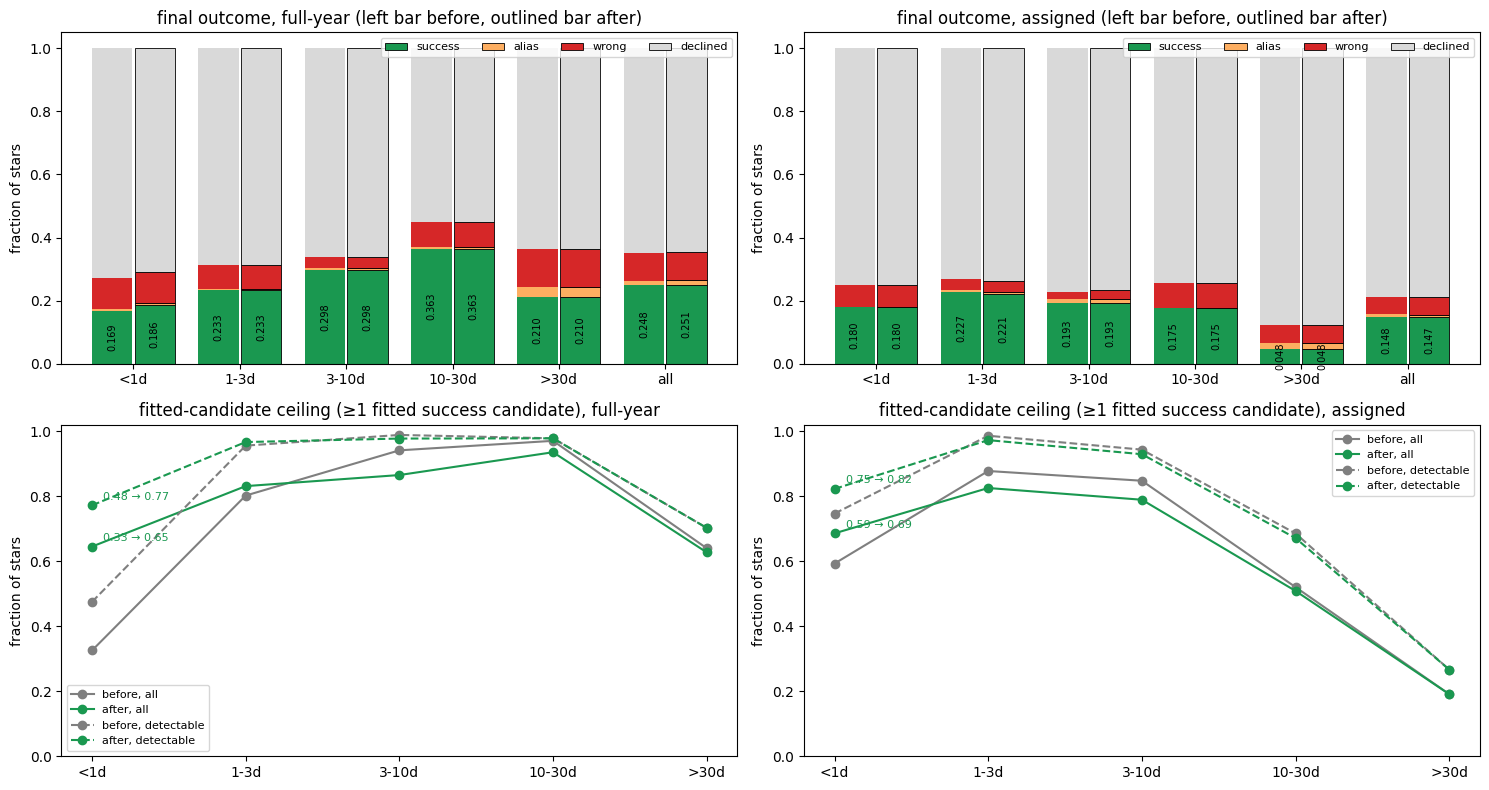

In [7]:
F.fig_scorecard_bins(); plt.show()

In [8]:
pd.read_csv(F.DATA / 'scorecard_bins.csv').round(3)

,mode,when,bin,union_recall,n,correct,diffrot,half,double,wrong,none,success,alias
0,fy,before,1-3d,0.971,172,0.203,0.029,0.006,0.000,0.076,0.686,0.233,0.006
1,fy,before,10-30d,0.988,171,0.281,0.082,0.000,0.006,0.082,0.550,0.363,0.006
2,fy,before,3-10d,0.965,171,0.234,0.064,0.000,0.006,0.035,0.661,0.298,0.006
3,fy,before,<1d,0.442,172,0.134,0.035,0.000,0.006,0.099,0.727,0.169,0.006
4,fy,before,>30d,0.917,314,0.166,0.045,0.032,0.000,0.121,0.637,0.210,0.032
5,fy,before,all,0.865,1000,0.198,0.050,0.011,0.003,0.088,0.650,0.248,0.014
6,fy,after,1-3d,0.983,172,0.198,0.035,0.006,0.000,0.076,0.686,0.233,0.006
7,fy,after,10-30d,0.982,171,0.281,0.082,0.000,0.006,0.082,0.550,0.363,0.006
8,fy,after,3-10d,0.942,171,0.234,0.064,0.000,0.006,0.035,0.661,0.298,0.006
9,fy,after,<1d,0.698,172,0.140,0.047,0.000,0.006,0.099,0.709,0.186,0.006


Why the newly fitted sub-day success candidates are still declined: gate failures on success candidates.

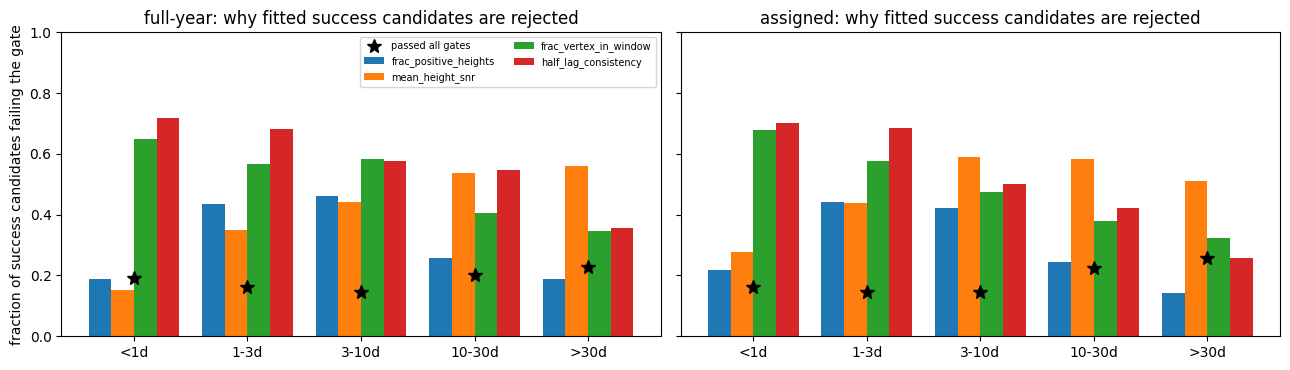

In [9]:
F.fig_gates(); plt.show()

In [10]:
pd.read_csv(F.DATA / 'gates_success_candidates.csv').round(3)

,mode,bin,n_candidates,n_stars,passed,only_half_lag,n_peaks,frac_positive_heights,mean_height_snr,frac_vertex_in_window,half_lag_consistency
0,fy,1-3d,422,143,0.164,0.045,0.000,0.436,0.351,0.566,0.682
1,fy,10-30d,439,160,0.200,0.014,0.000,0.257,0.538,0.405,0.547
2,fy,3-10d,458,148,0.144,0.000,0.000,0.461,0.443,0.583,0.576
3,fy,<1d,264,111,0.193,0.110,0.000,0.189,0.152,0.648,0.720
4,fy,>30d,490,197,0.227,0.000,0.039,0.188,0.561,0.347,0.355
5,asg,1-3d,400,142,0.145,0.035,0.000,0.442,0.440,0.578,0.685
6,asg,10-30d,208,87,0.226,0.005,0.019,0.245,0.582,0.380,0.423
7,asg,3-10d,372,135,0.145,0.005,0.016,0.422,0.591,0.473,0.500
8,asg,<1d,285,118,0.161,0.063,0.007,0.218,0.277,0.677,0.702
9,asg,>30d,139,60,0.259,0.000,0.007,0.144,0.511,0.324,0.259


## 4. Interleaved timing of the ranking change

In [11]:
b = pd.read_csv(F.DATA / 'bench_ranking.csv')
per = b.groupby(['star_id', 'rank_by'])[['gen_seconds', 'fit_seconds', 'n_tried']].median().unstack()
tot = per['gen_seconds'] + per['fit_seconds']
print(per.median().round(4)); print('median paired total ratio hybrid/power:', round((tot['hybrid'] / tot['power']).median(), 3))

             rank_by
gen_seconds  hybrid      0.0952
             power       0.0752
fit_seconds  hybrid      3.0173
             power       3.1483
n_tried      hybrid     22.5000
             power      24.0000
dtype: float64
median paired total ratio hybrid/power: 0.928


## 5. Phase 2: optional methods on top of the fixed pool

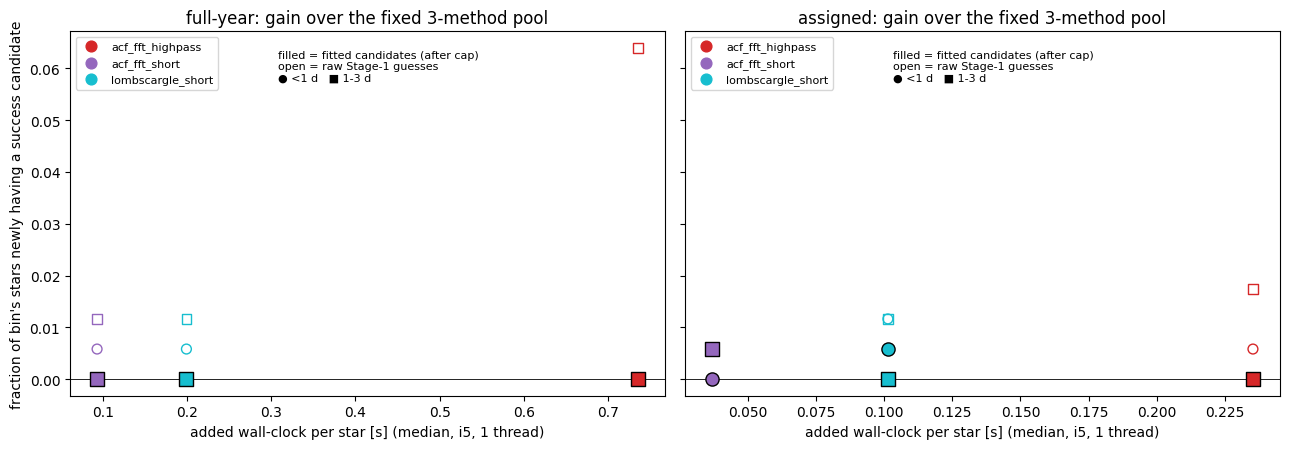

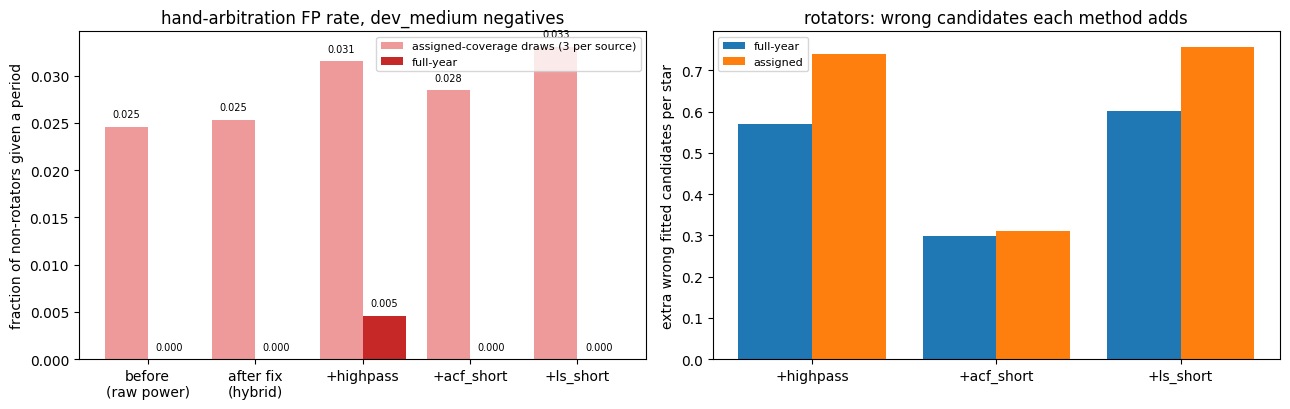

In [12]:
s, fp = F.phase2_summary()
F.fig_tradeoff(s); plt.show()
F.fig_fp(s, fp); plt.show()

In [13]:
s.set_index(['mode', 'method']).T.round(3)

mode                                 asg                                                 fy                                  
method                  acf_fft_highpass   acf_fft_short lombscargle_short acf_fft_highpass   acf_fft_short lombscargle_short
config                     base+highpass  base+acf_short     base+ls_short    base+highpass  base+acf_short     base+ls_short
added_seconds_median            0.235299        0.036806           0.10135         0.735452        0.093379          0.199432
added_seconds_mean              0.284406        0.072141          0.137977          0.75406        0.100772           0.22146
base_fit_seconds_median         1.356457        1.356457          1.356457         2.375866        2.375866          2.375866
extra_wrong_fitted                  0.74            0.31             0.757             0.57           0.298             0.602
d_success                          0.003           0.003               0.0            0.005           0.001               0.0
d_wrong                            0.006           0.003             0.004            0.007          -0.001               0.0
gain_<1d                             0.0             0.0          0.005814              0.0             0.0               0.0
loss_<1d                             0.0             0.0               0.0              0.0             0.0               0.0
gain_det_<1d                         0.0             0.0               0.0              0.0             0.0               0.0
rawgain_<1d                     0.005814        0.005814          0.011628              0.0        0.005814          0.005814
dsucc_<1d                            0.0             0.0         -0.005814         0.005814        0.005814               0.0
gain_1-3d                            0.0        0.005814               0.0              0.0             0.0               0.0
loss_1-3d                            0.0             0.0          0.005814              0.0             0.0               0.0
gain_det_1-3d                        0.0             0.0               0.0              0.0             0.0               0.0
rawgain_1-3d                    0.017442        0.005814          0.011628         0.063953        0.011628          0.011628
dsucc_1-3d                      0.011628        0.011628          0.005814         0.005814             0.0               0.0
gain_3-10d                      0.011696        0.005848          0.005848              0.0        0.005848          0.005848
loss_3-10d                           0.0             0.0               0.0              0.0        0.005848               0.0
gain_det_3-10d                       0.0             0.0               0.0              0.0             0.0               0.0
rawgain_3-10d                   0.023392        0.011696          0.011696         0.040936        0.035088          0.017544
dsucc_3-10d                     0.005848        0.005848               0.0        -0.005848        0.005848               0.0
gain_10-30d                     0.005848        0.011696          0.011696         0.017544        0.011696          0.005848
loss_10-30d                          0.0             0.0               0.0              0.0             0.0               0.0
gain_det_10-30d                      0.0             0.0               0.0              0.0             0.0               0.0
rawgain_10-30d                  0.064327        0.005848           0.02924         0.011696        0.005848               0.0
dsucc_10-30d                   -0.005848             0.0               0.0        -0.005848       -0.005848               0.0
gain_>30d                       0.003185             0.0               0.0              0.0             0.0               0.0
loss_>30d                            0.0             0.0               0.0              0.0             0.0               0.0
gain_det_>30d                   0.006667             0.0               0.0              0.0   

In [14]:
fp.round(4)

,fp_assigned_draws,fp_fullyear,fp_all,n_fitted_mean,fit_seconds_median
config,,,,,
base,0.0253,0.0000,0.0190,18.0207,0.7497
base+acf_short,0.0284,0.0000,0.0213,18.4303,0.7814
base+highpass,0.0315,0.0046,0.0248,18.9044,0.8153
base+ls_short,0.0330,0.0000,0.0248,18.9591,0.8089
base_old,0.0246,0.0000,0.0184,19.0593,0.9582
